---
title: "L6-07 · Process matrices and validity"
short_title: "Process matrices and validity"
subtitle: "A process matrix is whatever assigns probabilities to every choice of local quantum operations; demanding that those probabilities be non-negative and sum to 1 for every local choice gives W ≥ 0 plus linear constraints, and those constraints still allow processes with no definite causal order."
description: "Decide whether an operator is a valid bipartite process matrix by checking positivity and the complete set of linear normalization conditions, and explain why positivity alone is not enough."
tags: [level-6, coursebook]
---

(lesson-l6-07)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 120 minutes  
**Big idea.** A process matrix is whatever assigns probabilities to every choice of local quantum operations; demanding that those probabilities be non-negative and sum to 1 for every local choice gives W ≥ 0 plus linear constraints, and those constraints still allow processes with no definite causal order.  
**Before this lesson.** [L6-02](#lesson-l6-02), [L6-04](#lesson-l6-04), [L6-06](#lesson-l6-06)  
**Lab.** [The quantum switch](../../labs/09-quantum-switch.ipynb)
:::

## What you will be able to do

- Compute $p(a,b|x,y) = \operatorname{Tr}[W(M_{a|x}\otimes M_{b|y})]$ in a stated Choi convention, and show that it reduces to the Born rule when $W = \rho^{A_IB_I}\otimes 1^{A_OB_O}$.
- State and prove the linear characterization of bipartite process matrices, and use it to classify Pauli term types as allowed or forbidden.
- Construct a positive operator with the right trace that is not a process, and compute the total probability it assigns to a local unitary.
- Show that every causally separable process obeys the $3/4$ bound of the OCB game, and verify numerically that the OCB process exceeds it.

## Why this matters

Every circuit you have met so far comes with a time order: prepare, evolve, measure. Suppose instead that two laboratories each obey quantum theory locally, a system enters each laboratory once and leaves once, and nothing else is assumed about how the laboratories are connected. Which connections are allowed? A shared entangled state is one. A wire from Alice's output to Bob's input is another. Are there connections that are neither, nor a random choice between them?

The natural first guess is that any positive operator with the right trace will do, as for density matrices. It fails. The operator that wires Alice's output back into her own input is positive and has the right trace, yet it assigns total probability 4 if she does nothing and total probability 0 if she flips her qubit: a quantum version of the grandfather paradox. The validity conditions of Oreshkov, Costa and Brukner remove exactly such loops [@ocb]. What survives still includes processes that win a communication game more often than any definite order allows.

:::{dropdown} Key terms

**Quantum instrument**
: A family $\{\mathcal M_a\}_a$ of completely positive maps whose sum is trace preserving; outcome $a$ occurs and the output is $\mathcal M_a(\rho)$ up to normalization.

**Process matrix**
: An operator $W \ge 0$ on $A_IA_OB_IB_O$ that gives normalized probabilities $\operatorname{Tr}[W(M_A\otimes M_B)]$ for every pair of local instruments.

**Trace-and-replace map**
: ${}_XW = \frac{1^X}{d_X}\otimes\operatorname{Tr}_X W$: discard subsystem $X$ and put back the maximally mixed state.

**Causally separable**
: Bipartite: a convex mixture $qW^{A\prec B} + (1-q)W^{B\prec A}$ of processes compatible with a definite order.

**Causal inequality**
: A bound on observed correlations obeyed by every causally separable process, for a stated game and set of assumptions.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_07 as _lessonfigs

## Local laboratories and the generalized Born rule

Alice receives a system on her input space $A_I$ and sends one out on $A_O$; Bob has $B_I$ and $B_O$. In this lesson all four are qubits, $d = 2$. Each party chooses a setting ($x$ for Alice, $y$ for Bob) and applies a quantum instrument whose outcome is recorded ($a$, $b$). Nothing in the setup says whether Alice acts before Bob, after him, or neither. The object that connects the two laboratories is a single operator $W$ on $A_I\otimes A_O\otimes B_I\otimes B_O$ [@ocb].

:::{prf:definition} Instruments and the pairing convention
:label: def-l6-07-instrument
An **instrument** for Alice is a family of completely positive maps $\mathcal M_{a|x}: \mathcal L(A_I)\to\mathcal L(A_O)$ with $\sum_a \mathcal M_{a|x}$ trace preserving. Its **pairing operator** in this lesson is

$$M_{a|x}^{A_IA_O} = \Big[\sum_{i,j}|i\rangle\langle j|\otimes\mathcal M_{a|x}(|i\rangle\langle j|)\Big]^T = J_{a|x}^{\,T},$$

the full transpose of the Choi operator $J$ of [L6-02](#lesson-l6-02) (input factor first, unnormalized), which `qcai.science.choi` also returns. This is the convention of [@ocb]. $M \ge 0$ exactly when $\mathcal M$ is completely positive, and $\operatorname{Tr}_{A_O}\sum_a M_{a|x} = 1^{A_I}$ exactly when the sum is trace preserving.
:::

$$
p(a,b|x,y) = \operatorname{Tr}\big[W^{A_IA_OB_IB_O}\,(M_{a|x}^{A_IA_O}\otimes M_{b|y}^{B_IB_O})\big]
$$ (eq-l6-07-born)

Equation [](#eq-l6-07-born) is the **generalized Born rule**. Probabilities are linear in $W$ and in each local operation, as they must be for mixtures of procedures to give mixtures of statistics.

```{mermaid}
graph LR
  W1[W: the environment] -->|A_I| A[Alice: instrument x, outcome a]
  A -->|A_O| W2[W: the environment]
  W1 -->|B_I| B[Bob: instrument y, outcome b]
  B -->|B_O| W2
```

*The process matrix $W$ is everything outside the two laboratories. It supplies the inputs $A_I$, $B_I$ and absorbs the outputs $A_O$, $B_O$, without a stated order between Alice and Bob.*

:::{figure} ../../_static/animations/l6_07_born_pairing.mp4
:alt: Two laboratory boxes A and B inside a violet region labeled W, the formula p equals trace of W times the tensor product of the two instruments, and a three-step derivation ending in the ordinary Born rule.
:width: 100%

The process matrix is the environment of both laboratories. For a shared state with discarded outputs, the generalized Born rule collapses to the ordinary one, because $\operatorname{Tr}_{A_O} M_{a|x} = E_{a|x}$.
:::

:::{dropdown} What the animation shows
A violet region labeled W surrounds two boxes, Alice's laboratory A with wires A_I below and A_O above, and Bob's laboratory B with B_I and B_O. The formula $p(a,b|x,y) = \operatorname{Tr}[W(M_{a|x}\otimes M_{b|y})]$ appears, with the note that $M$ is the transposed Choi operator of each local completely positive map. The special case $W = \rho\otimes 1$ is then worked in three steps: $p = \operatorname{Tr}[(\rho\otimes 1)(M_{a|x}\otimes M_{b|y})]$, then $p = \operatorname{Tr}[\rho(\operatorname{Tr}_{A_O}M_{a|x}\otimes\operatorname{Tr}_{B_O}M_{b|y})]$, then $p = \operatorname{Tr}[\rho(E_{a|x}\otimes F_{b|y})]$, using $\operatorname{Tr}_{A_O} M_{a|x} = E_{a|x}$. The last line is boxed as the ordinary Born rule for a shared state. Finally a violet curved wire connects A's output to B's input, a different W in which Alice can signal to Bob.
:::

:::{prf:proposition} Shared states are processes
:label: prop-l6-07-state
Let $W = \rho^{A_IB_I}\otimes 1^{A_OB_O}$ with $\rho$ a density operator. Then $p(a,b|x,y) = \operatorname{Tr}[\rho\,(E_{a|x}\otimes F_{b|y})]$, where $E_{a|x} = \sum_k K_k^\dagger K_k$ is the POVM element of the instrument $\mathcal M_{a|x}(\cdot) = \sum_k K_k \cdot K_k^\dagger$, and similarly $F_{b|y}$ for Bob.
:::

:::{prf:proof}
Tracing out $A_O$ and $B_O$ against the identity gives $p = \operatorname{Tr}[\rho(\operatorname{Tr}_{A_O}M_{a|x}\otimes\operatorname{Tr}_{B_O}M_{b|y})]$. Partial trace commutes with transposition, and $\operatorname{Tr}_{A_O}J_{a|x} = \sum_{i,j}|i\rangle\langle j|\operatorname{Tr}[\mathcal M_{a|x}(|i\rangle\langle j|)] = \sum_{i,j}|i\rangle\langle j|\,\langle j|E_{a|x}|i\rangle = E_{a|x}^T$. Transposing once more, $\operatorname{Tr}_{A_O} M_{a|x} = E_{a|x}$. The same holds for Bob. $\square$
:::

:::{warning} Conventions travel together
Other papers put the transpose on $W$, on the input factor only, or use the link product. Each choice changes the formula for $W$ and the constraints in step. Examples with real matrices (the identity wire, Pauli $Z$ and $X$) cannot reveal a mismatch, because transposition does nothing to them; complex ones can. Import a process matrix and its pairing rule from the same source.
:::

## Validity: probabilities for every local choice

:::{prf:definition} Valid process matrix
:label: def-l6-07-valid
An operator $W$ on $A_IA_OB_IB_O$ is a **valid process matrix** if (i) $W \ge 0$ and (ii) $\operatorname{Tr}[W(M_A\otimes M_B)] = 1$ for every pair of pairing operators $M_A$, $M_B$ of completely positive trace-preserving (CPTP) maps. Condition (ii) says that the outcome probabilities of any two instruments add up to 1. Condition (i) is what one obtains by demanding non-negative probabilities also when the local operations act on parts of an arbitrary shared ancillary state [@ocb]; with $W \ge 0$ every pairing with completely positive maps is automatically non-negative, since the trace of a product of two positive operators is non-negative.
:::

Condition (ii) quantifies over infinitely many pairs of channels. The next theorem turns it into finitely many linear equations. Write ${}_XW = \frac{1^X}{d_X}\otimes\operatorname{Tr}_XW$ for the **trace-and-replace** map on subsystem $X$, and compose these maps for several subsystems, for example ${}_{A_OB_O}W$ [@process].

:::{prf:theorem} Linear characterization of bipartite processes
:label: thm-l6-07-valid
A Hermitian $W$ satisfies condition (ii) of [](#def-l6-07-valid) if and only if $\operatorname{Tr}W = d_{A_O}d_{B_O}$ and the three equations [](#eq-l6-07-linear) hold [@process]. Hence $W$ is a valid process matrix if and only if it is positive semidefinite, has trace $d_{A_O}d_{B_O}$, and satisfies [](#eq-l6-07-linear).
:::

$$
{}_{B_IB_O}W = {}_{A_OB_IB_O}W,\qquad {}_{A_IA_O}W = {}_{A_IA_OB_O}W,\qquad W = {}_{A_O}W + {}_{B_O}W - {}_{A_OB_O}W
$$ (eq-l6-07-linear)

:::{prf:proof}
Let $\mathcal C_A = \{M \ge 0 : \operatorname{Tr}_{A_O}M = 1^{A_I}\}$ be the set of pairing operators of CPTP maps. Its affine hull is $\mathcal H_A = \{M = M^\dagger : \operatorname{Tr}_{A_O}M = 1^{A_I}\}$: the point $1/d_{A_O}$ lies in $\mathcal C_A$ and is positive definite, so $1/d_{A_O} + \epsilon S \in \mathcal C_A$ for every Hermitian $S$ with $\operatorname{Tr}_{A_O}S = 0$ and small $\epsilon$. The map $f(M_A, M_B) = \operatorname{Tr}[W(M_A\otimes M_B)]$ is affine in each argument, so $f = 1$ on $\mathcal C_A\times\mathcal C_B$ if and only if $f = 1$ on $\mathcal H_A\times\mathcal H_B$. Write $M_A = 1/d_{A_O} + S$, $M_B = 1/d_{B_O} + T$ with $\operatorname{Tr}_{A_O}S = 0$, $\operatorname{Tr}_{B_O}T = 0$, and expand:

(a) $S = T = 0$ gives $\operatorname{Tr}W = d_{A_O}d_{B_O}$.

(b) $T = 0$ and arbitrary $S$: $\operatorname{Tr}[(\operatorname{Tr}_{B_IB_O}W)S] = 0$ for all $S$ in the range of $1 - {}_{A_O}$, the Hilbert-Schmidt orthogonal projector onto operators with $\operatorname{Tr}_{A_O}S = 0$. This holds exactly when $(1 - {}_{A_O})\operatorname{Tr}_{B_IB_O}W = 0$, the first equation.

(c) $S = 0$ and arbitrary $T$ gives the second equation in the same way.

(d) Both nonzero: $\operatorname{Tr}[W(S\otimes T)] = 0$ for all such $S$, $T$. Products of the two ranges span the range of $(1-{}_{A_O})(1-{}_{B_O})$, so this holds exactly when $(1-{}_{A_O})(1-{}_{B_O})W = 0$, which expands to the third equation.

Each step is reversible, which proves the equivalence. $\square$
:::

The equations are easiest to read in a Pauli expansion $W = \frac14\sum c_{\mu\nu\kappa\lambda}\,\sigma_\mu^{A_I}\sigma_\nu^{A_O}\sigma_\kappa^{B_I}\sigma_\lambda^{B_O}$. The map ${}_X$ deletes every term that is nontrivial on $X$ and keeps the others. Group terms by **type**, the set of subsystems on which they act nontrivially; a type with $k$ nontrivial factors spans $3^k$ real dimensions. The third equation forbids every type containing both $A_O$ and $B_O$. The first forbids types containing $A_O$ that are trivial on both $B_I$ and $B_O$, and the second forbids the mirror image.

:::{figure} ../../_static/animations/l6_07_term_sieve.mp4
:alt: A four by four grid of tiles indexed by Alice's part and Bob's part of a Pauli term, with dimensions 1, 3, 9, 27, 81; three rules strike out eight tiles in red and the remaining tiles are colored by meaning.
:width: 100%

The linear conditions as a sieve on the 16 term types. Eight types survive, of total dimension $1 + 3 + 3 + 9 + 9 + 27 + 9 + 27 = 88$ out of 256.
:::

:::{dropdown} What the animation shows
Rows of the grid are Alice's part of a term type (1, $A_I$, $A_O$, $A_IA_O$) and columns are Bob's part (1, $B_I$, $B_O$, $B_IB_O$); each tile shows the real dimension $3^k$, and the dimensions add to $4^4 = 256$. Rule 1, $(1-{}_{A_O})(1-{}_{B_O})W = 0$, strikes the four tiles that contain both outputs. Rule 2, ${}_{B_IB_O}W = {}_{A_OB_IB_O}W$, strikes $A_O$ and $A_IA_O$ paired with Bob's trivial part. Rule 3 strikes $B_O$ and $B_IB_O$ paired with Alice's trivial part. The eight survivors are colored: cyan for shared-state terms (1, $A_I$, $B_I$, $A_IB_I$), violet for terms by which A can signal to B ($A_OB_I$, $A_IA_OB_I$), and amber for B signaling to A ($A_IB_O$, $A_IB_IB_O$). The final line reads $1 + 3 + 3 + 9 + 9 + 27 + 9 + 27 = 88$.
:::

:::{prf:remark} A projector form
Araújo and coauthors package the three equations into one projector, $L_V(W) = {}_{A_O}W + {}_{B_O}W - {}_{A_OB_O}W - {}_{B_IB_O}W + {}_{A_OB_IB_O}W - {}_{A_IA_O}W + {}_{A_IA_OB_O}W$, so that the linear conditions read $W = L_V(W)$ [@process]. For qubit laboratories its rank is $88$, matching the count in the animation; the code below checks both facts.
:::

## Positivity is not enough

:::{prf:proposition} A positive operator that is not a process
:label: prop-l6-07-loop
Let $|1\rangle\!\rangle = |00\rangle + |11\rangle$ and $W_{\rm loop} = |1\rangle\!\rangle\langle\!\langle 1|^{A_IA_O}\otimes|0\rangle\langle 0|^{B_I}\otimes 1^{B_O}$. Then $W_{\rm loop} \ge 0$ and $\operatorname{Tr}W_{\rm loop} = 2\cdot 1\cdot 2 = 4 = d_{A_O}d_{B_O}$, but if Alice applies a unitary $U$ and Bob applies any channel, the total probability is $|\operatorname{Tr}U|^2$. It equals $4$ for $U = 1$ and $0$ for $U = X$.
:::

:::{prf:proof}
$W_{\rm loop}$ is a tensor product of positive operators. Bob's factor $|0\rangle\langle 0|\otimes 1$ pairs with any CPTP pairing operator to give $\operatorname{Tr}[|0\rangle\langle 0|\operatorname{Tr}_{B_O}M_B] = \langle 0|1|0\rangle = 1$. For Alice, $M_U = (|U\rangle\!\rangle\langle\!\langle U|)^T$ with $|U\rangle\!\rangle = (1\otimes U)|1\rangle\!\rangle$. Because $|1\rangle\!\rangle$ is a real vector, $\langle\!\langle 1|M_U|1\rangle\!\rangle = |\langle\!\langle 1|(1\otimes U)|1\rangle\!\rangle|^2 = |\sum_j\langle j|U|j\rangle|^2 = |\operatorname{Tr}U|^2$. $\square$
:::

:::{figure} ../../_static/animations/l6_07_loop.mp4
:alt: Alice's laboratory with a red wire from its output back to its input, a derivation of the total probability as the squared trace of U, and a graph of that total as U rotates, swinging between 4 and 0 while the valid value stays at 1.
:width: 100%

The loop wire is positive and has the right trace, yet the total probability depends on what Alice does: $|\operatorname{Tr} U|^2 = 4\cos^2(\theta/2)$ for $U = e^{-i\theta Y/2}$.
:::

:::{dropdown} What the animation shows
A red curved wire leaves Alice's output $A_O$ and enters her own input $A_I$; the operator is $W_{\rm loop} = |1\rangle\!\rangle\langle\!\langle 1|^{A_IA_O}$ on her side, positive with trace 2. The pairing is derived in three steps: $\operatorname{Tr}[W_{\rm loop}M_U] = \langle\!\langle 1|M_U|1\rangle\!\rangle = |\langle\!\langle 1|(1\otimes U)|1\rangle\!\rangle|^2 = |\operatorname{Tr}U|^2$. With $U = e^{-i\theta Y/2}$ this is $|\operatorname{Tr} U|^2 = 4\cos^2(\theta/2)$. A graph of total probability against $\theta$ from 0 to $2\pi$ is traced in red while a dashed cyan line marks the value 1 that every valid process gives. The red curve starts at 4 (identity), falls to 0 at $\theta = \pi$ (a flip), and returns to 4.
:::

The loop is a closed causal curve for a qubit. If Alice does nothing, every input value is consistent with itself and the probabilities overcount; if she flips the qubit, no value is consistent and they vanish. In the Pauli expansion, $|1\rangle\!\rangle\langle\!\langle 1| = \frac12(1\otimes 1 + X\otimes X - Y\otimes Y + Z\otimes Z)$ contains terms of type $A_IA_O$ with trivial Bob part, which the first equation of [](#eq-l6-07-linear) forbids. The same operator on $A_O B_I$ instead of $A_I A_O$ is a perfectly good process, a wire from Alice to Bob: the two operators have identical spectra, and only the linear conditions tell them apart.


In [2]:
_show(_lessonfigs.loop_mixture())

**Explore.** Mix the valid wire $W_{\rm chan}$ (Alice to Bob) with the loop $W_{\rm loop}$. Every mixture is positive, but its probabilities sum to 1 for all of Alice's rotations only at $\lambda = 0$.

:::{dropdown} What the figure shows
The first panel plots the total probability $(1-\lambda) + \lambda\cdot 4\cos^2(\theta/2)$ against Alice's rotation angle $\theta$ from $0^\circ$ to $360^\circ$, with a dashed line at the required value 1; the slider sets $\lambda$ from 0 to 1 in steps of 0.1. At $\lambda = 0$ the curve is flat at 1; at $\lambda = 1$ it runs from 4 down to 0 and back. The second panel plots the smallest eigenvalue of the mixture against $\lambda$: it is 0 for every $\lambda$, so positivity never fails.
:::

:::{prf:example} Linear conditions without positivity
:label: ex-l6-07-negative
Positivity cannot be dropped either. Take $\sigma = \frac14(1 + 1.5\,Z\otimes Z)$ on $A_IB_I$, a unit-trace Hermitian operator with eigenvalue $(1 - 1.5)/4 = -1/8$, and $W_{\rm neg} = \sigma\otimes 1^{A_OB_O}$. Its only types are $1$ and $A_IB_I$, so it satisfies [](#eq-l6-07-linear) and gives total probability 1 for every pair of channels. But if both parties measure $Z$, the outcome pair $(0, 1)$ gets probability $\langle 01|\sigma|01\rangle = -1/8$.
:::


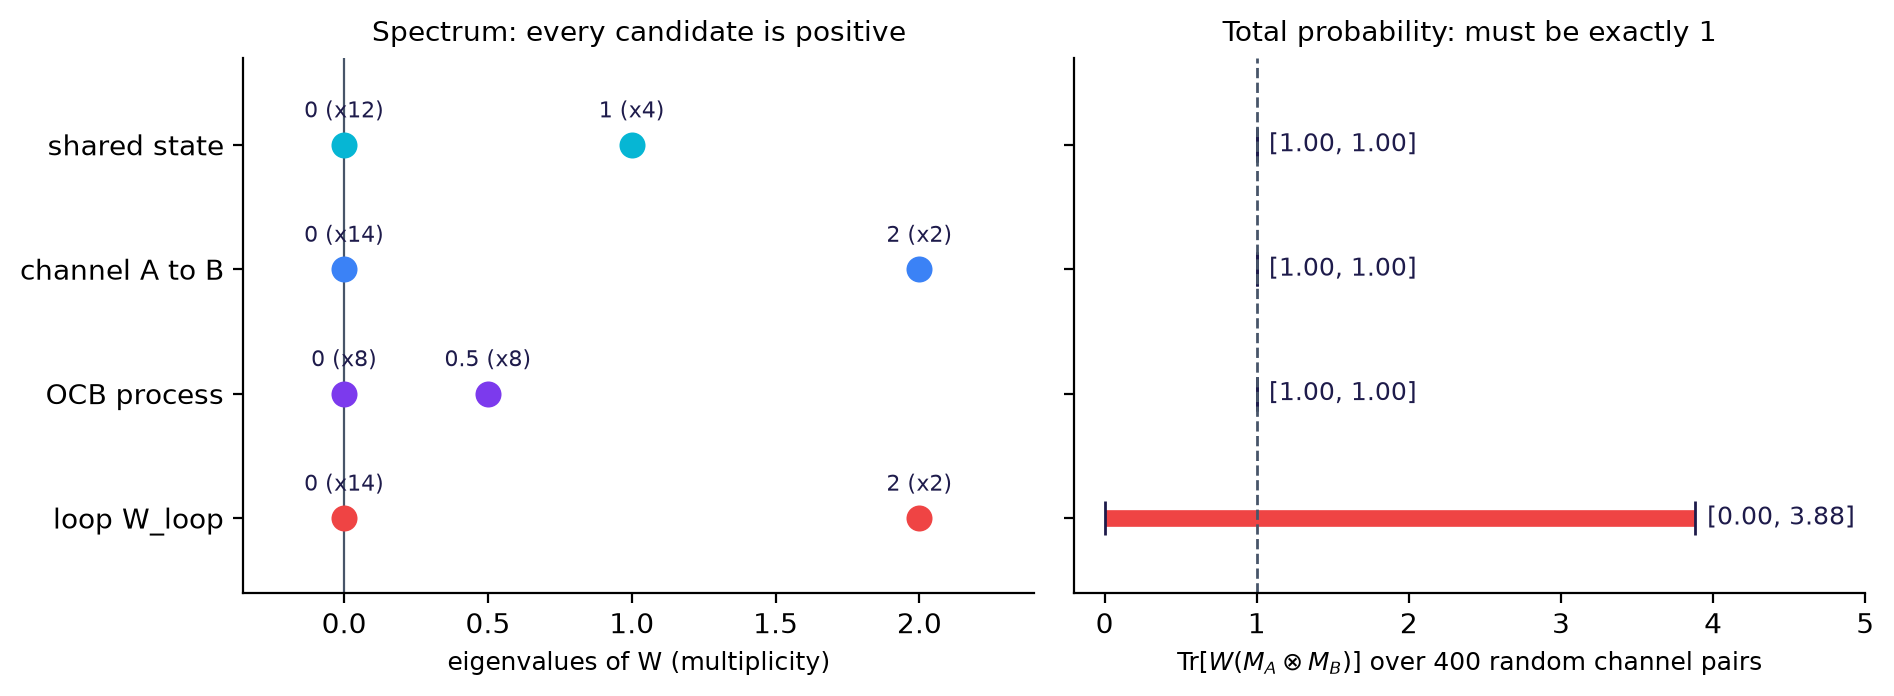

In [3]:
_show_mpl(_lessonfigs.candidates_figure())

*Four positive operators of trace 4. Left: their spectra. Right: the range of $\operatorname{Tr}[W(M_A\otimes M_B)]$ over 400 random pairs of local channels. The shared state, the wire from A to B and the OCB process give exactly 1; the loop, with the same spectrum as the wire, ranges from 0 to almost 4.*

## Order inside a process: separable and nonseparable

:::{prf:definition} Definite order and causal separability
:label: def-l6-07-separable
A valid $W$ is **compatible with $A\prec B$** (Alice before Bob) if $W = {}_{B_O}W$ and ${}_{B_IB_O}W = {}_{A_OB_IB_O}W$: Bob's output goes nowhere, and Alice's marginal does not depend on her own output. Compatibility with $B\prec A$ is defined by exchanging the labels. A bipartite $W$ is **causally separable** if $W = q\,W^{A\prec B} + (1-q)\,W^{B\prec A}$ for some $q\in[0,1]$ and processes of the two kinds; otherwise it is **causally nonseparable** [@ocb; @process].
:::

In the term-type picture, $W^{A\prec B}$ uses only cyan and violet tiles, and $W^{B\prec A}$ only cyan and amber. A process with both violet and amber terms may still be separable, because a mixture also has both. Deciding separability is a semidefinite feasibility problem; its dual gives **causal witnesses**, Hermitian $S$ with $\operatorname{Tr}[SW] \ge 0$ for every separable $W$ [@process]. Here we use a different route, a game.

:::{prf:theorem} Causally separable processes obey the OCB bound
:label: thm-l6-07-ocb
In the OCB game of [L6-06](#lesson-l6-06), Alice receives a uniformly random bit $a$ and Bob uniformly random bits $b$ and $b'$, all independent. If $b' = 0$, the round is won when Alice outputs $x = b$; if $b' = 1$, it is won when Bob outputs $y = a$. For every causally separable process and all local instruments, $p_{\rm succ} \le 3/4$ [@ocb]. This game differs from the guess-your-neighbor's-input game of Branciard et al., in which each party has one input bit and the causal bound is $1/2$ [@branciard2016].
:::

:::{prf:proof}
Probabilities are linear in $W$, so it suffices to treat $W^{A\prec B}$ and $W^{B\prec A}$ separately. If $W$ is compatible with $A\prec B$, then $W = {}_{B_O}W = W'\otimes 1^{B_O}/d_{B_O}$. For any instrument of Bob, the sum $N$ of its pairing operators satisfies $\operatorname{Tr}_{B_O}N = 1^{B_I}$, so Alice's marginal $\operatorname{Tr}[W(M_{x|a}\otimes N)] = \operatorname{Tr}[W'(M_{x|a}\otimes 1^{B_I})]/d_{B_O}$ does not depend on Bob's instrument, hence not on $b$ or $b'$. The statistics are those of a causally ordered strategy in the sense of [L6-06](#lesson-l6-06), and its theorem applies: the $b' = 0$ rounds are won with probability exactly $1/2$, the others at most 1, so $p_{\rm succ} \le 3/4$. The case $B\prec A$ is symmetric, and a convex combination of two numbers at most $3/4$ is at most $3/4$. $\square$
:::

$$
W_{\rm OCB} = \tfrac14\Big[1 + \tfrac{1}{\sqrt2}\big(Z^{A_O}Z^{B_I} + Z^{A_I}X^{B_I}Z^{B_O}\big)\Big]
$$ (eq-l6-07-ocb)

The first term in [](#eq-l6-07-ocb) is of the violet type $A_OB_I$, the second of the amber type $A_IB_IB_O$; both are allowed, and $\operatorname{Tr}W_{\rm OCB} = 4$. The two Pauli products anticommute (they meet $Z$ and $X$ on $B_I$) and each squares to 1, so their sum has eigenvalues $\pm\sqrt2$ and $W_{\rm OCB}$ has eigenvalues $0$ and $1/2$: it is positive and hence valid [@ocb]. With the instruments below, it wins with probability $(2+\sqrt2)/4 \approx 0.854$, so by [](#thm-l6-07-ocb) it is causally nonseparable. Alice measures $A_I$ in the $Z$ basis to get $x$ and prepares $|a\rangle$ on $A_O$. If $b' = 1$, Bob measures $B_I$ in the $Z$ basis to get $y$ (and prepares $|0\rangle$); if $b' = 0$, he measures $B_I$ in the $X$ basis with outcome $y$ and prepares $|b\oplus y\rangle$ on $B_O$.

:::{figure} ../../_static/animations/l6_07_causal_game.mp4
:alt: The rules of the OCB causal game, the argument for the bound three quarters, and a graph of the winning probability of the noisy OCB process against visibility crossing the bound at one over root two.
:width: 100%

Any mixture of definite orders wins at most $3/4$. The OCB process mixed with white noise wins with $\tfrac12 + v\tfrac{\sqrt2}{4}$, which beats the bound for $v > 1/\sqrt2$.
:::

:::{dropdown} What the animation shows
The rules appear: $a$, $b$, $b'$ are random bits; if $b' = 0$ Alice must output $x = b$; if $b' = 1$ Bob must output $y = a$. The argument follows: if A acts first, nothing about $b$ reaches Alice, so on the $b' = 0$ rounds her guess wins with probability 1/2, and $p_{\rm succ} \le \frac12\cdot 1 + \frac12\cdot\frac12 = 3/4$; mixtures of orders are still at most 3/4. On the right, the noisy process $W_v = vW_{\rm OCB} + (1-v)\frac14 1$ has $p_{\rm succ} = \tfrac12 + v\tfrac{\sqrt2}{4}$. A violet point traces this line as $v$ grows from 0, crosses the dashed bound 3/4 at $v = 1/\sqrt2$, and ends at $(2+\sqrt2)/4 \approx 0.854$ for $v = 1$. The closing caption says that a value above 3/4 rules out every mixture of definite orders.
:::

Everything in this lesson, checked numerically: the projector $L_V$ and its rank 88, the generalized Born rule with transposed Choi operators, total probabilities over random local channels, the loop, a non-positive operator that satisfies the linear conditions, and the OCB game with white noise.


In [4]:
import itertools
import numpy as np

I2 = np.eye(2); X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]]); Z = np.diag([1.0, -1.0]).astype(complex)

def kron(*ops):
    out = np.array([[1.0 + 0j]])
    for m in ops:
        out = np.kron(out, m)
    return out

def proj(v):
    v = np.asarray(v, dtype=complex); return np.outer(v, v.conj()) / np.vdot(v, v).real

# subsystem order A_I, A_O, B_I, B_O (qubits).  Trace-and-replace: _X W = 1/d (x) Tr_X W
POS = {"AI": 0, "AO": 1, "BI": 2, "BO": 3}
def tr_rep(W, *names):
    T = W.reshape([2] * 8)
    for n in names:
        k = POS[n]
        t = np.trace(T, axis1=k, axis2=k + 4)
        t = np.expand_dims(np.expand_dims(t, k), k + 4)
        shape = [2 if j in (k, k + 4) else 1 for j in range(8)]
        T = t * np.eye(2).reshape(shape) / 2
    return T.reshape(16, 16)

def L_V(W):   # projector onto the linear span of valid processes (Araujo et al. 2015)
    return (tr_rep(W, "AO") + tr_rep(W, "BO") - tr_rep(W, "AO", "BO") - tr_rep(W, "BI", "BO")
            + tr_rep(W, "AO", "BI", "BO") - tr_rep(W, "AI", "AO") + tr_rep(W, "AI", "AO", "BO"))

def is_valid(W, tol=1e-9):
    return (np.linalg.eigvalsh(W).min() > -tol and abs(np.trace(W).real - 4) < tol
            and np.allclose(L_V(W), W, atol=tol))

# 1. L_V is a projector of rank 88 = 1 + 3 + 3 + 9 + 9 + 27 + 9 + 27
M = np.array([L_V(np.eye(256)[k].reshape(16, 16)).reshape(256) for k in range(256)]).T
print("projector:", np.allclose(M @ M, M), " rank:", np.linalg.matrix_rank(M))

# 2. the pairing: transposed Choi operators (input (x) output) of local CP maps
def choi_T(kraus):
    J = np.zeros((4, 4), dtype=complex)
    for i in range(2):
        for j in range(2):
            E = np.zeros((2, 2), dtype=complex); E[i, j] = 1
            J += np.kron(E, sum(K @ E @ K.conj().T for K in kraus))
    return J.T

def random_cptp(rng, n):
    G = rng.normal(size=(2 * n, 2)) + 1j * rng.normal(size=(2 * n, 2))
    Q, _ = np.linalg.qr(G)
    return [Q[2 * k:2 * k + 2] for k in range(n)]

LINK = np.outer([1, 0, 0, 1], [1, 0, 0, 1]).astype(complex)          # |1>><<1|
rho0 = proj([1, 0])
W_chan = kron(rho0, LINK, I2)                                        # A_O wired to B_I
W_ocb = 0.25 * (np.eye(16) + (kron(I2, Z, Z, I2) + kron(Z, I2, X, Z)) / np.sqrt(2))
W_loop = kron(LINK, rho0, I2)                                        # A_O wired back to A_I
rng = np.random.default_rng(3)
pairs = [(random_cptp(rng, 1 + k % 3), random_cptp(rng, 1 + (k // 3) % 3)) for k in range(300)]
for name, W in [("channel", W_chan), ("OCB", W_ocb), ("loop", W_loop)]:
    tot = [np.trace(W @ np.kron(choi_T(a), choi_T(b))).real for a, b in pairs]
    print(f"{name:8s} min eig {np.linalg.eigvalsh(W).min():+.3f}  Tr W {np.trace(W).real:.0f}  "
          f"valid {is_valid(W)}  total prob in [{min(tot):.3f}, {max(tot):.3f}]")
assert is_valid(W_chan) and is_valid(W_ocb) and not is_valid(W_loop)

# the identity wire A_O -> B_I carries Alice's output state to Bob (complex input, random channel)
psi = np.array([0.6, 0.8j]); rho_c = np.outer(psi, psi.conj()); K = random_cptp(rng, 2)
T = (np.kron(rho_c, LINK) @ np.kron(choi_T(K), I2)).reshape([2] * 6)
print("wire delivers M(rho):", np.allclose(np.einsum("abcabd->cd", T), sum(k @ rho_c @ k.conj().T for k in K)))

# 3. the loop: total probability |Tr U|^2 for Alice's unitary U, Bob doing anything
for U, lab in [(I2, "identity"), (X, "flip X"), (Y, "Y")]:
    t = np.trace(W_loop @ np.kron(choi_T([U]), choi_T([I2]))).real
    print(f"loop with U = {lab:8s}: total {t:.3f}   |Tr U|^2 = {abs(np.trace(U)) ** 2:.3f}")

# 4. linear conditions hold but W is not positive: a negative probability
sigma = 0.25 * (np.eye(4) + 1.5 * np.kron(Z, Z))                    # 'state' on A_I B_I, eigenvalue -1/8
W_neg = np.einsum("abcd,ef,gh->aebgcfdh", sigma.reshape(2, 2, 2, 2), I2, I2).reshape(16, 16)
print("W_neg in span:", np.allclose(L_V(W_neg), W_neg), " min eig", np.linalg.eigvalsh(W_neg).min())
p01 = np.trace(W_neg @ np.kron(np.kron(proj([1, 0]), proj([1, 0])), np.kron(proj([0, 1]), proj([1, 0])))).real
print("p(Alice 0, Bob 1) =", p01)

# 5. the OCB game: causal bound 3/4
def success(W):
    z, xb = [proj([1, 0]), proj([0, 1])], [proj([1, 1]), proj([1, -1])]
    s = 0.0
    for a, b, bp in itertools.product((0, 1), repeat=3):
        for x, y in itertools.product((0, 1), repeat=2):
            MA = np.kron(z[x].T, z[a]).T          # course Choi J = Pi^T (x) sigma enters as M = J^T
            MB = np.kron(z[y].T, z[0]).T if bp == 1 else np.kron(xb[y].T, z[b ^ y]).T   # b' = 1: Bob guesses a
            s += np.trace(W @ np.kron(MA, MB)).real * ((y == a) if bp == 1 else (x == b)) / 8
    return s
print("OCB success", round(success(W_ocb), 4), " (2+sqrt2)/4 =", round((2 + np.sqrt(2)) / 4, 4))
for v in (0.6, 1 / np.sqrt(2), 0.8):
    Wv = v * W_ocb + (1 - v) * np.eye(16) / 4
    print(f"v = {v:.3f}: valid {is_valid(Wv)}, success {success(Wv):.4f}")

projector: True  rank: 88
channel  min eig +0.000  Tr W 4  valid True  total prob in [1.000, 1.000]
OCB      min eig +0.000  Tr W 4  valid True  total prob in [1.000, 1.000]
loop     min eig +0.000  Tr W 4  valid False  total prob in [0.000, 3.807]
wire delivers M(rho): True
loop with U = identity: total 4.000   |Tr U|^2 = 4.000
loop with U = flip X  : total 0.000   |Tr U|^2 = 0.000
loop with U = Y       : total 0.000   |Tr U|^2 = 0.000
W_neg in span: True  min eig -0.125
p(Alice 0, Bob 1) = -0.125
OCB success 0.8536  (2+sqrt2)/4 = 0.8536
v = 0.600: valid True, success 0.7121
v = 0.707: valid True, success 0.7500
v = 0.800: valid True, success 0.7828


:::{important} Nonseparable is not the same as violating a causal inequality
Violating [](#thm-l6-07-ocb) proves nonseparability without trusting the instruments, as a Bell test does for entanglement. The converse fails: some causally nonseparable processes violate no causal inequality, the quantum switch of [L6-08](#lesson-l6-08) among them, so their nonseparability cannot be certified by a causal-inequality violation; the certification used for them is a causal witness built on trusted, characterized operations [@process].
:::

## Worked example

:::{admonition} Is a wire from Alice to Bob a valid process?
:class: tip

Let $W_{\rm chan} = |0\rangle\langle 0|^{A_I}\otimes|1\rangle\!\rangle\langle\!\langle 1|^{A_OB_I}\otimes 1^{B_O}$. Show that it is valid, that it is compatible with $A\prec B$, and compute $p(a,b|x,y)$ when Alice applies the instrument $\mathcal M_{a|x}$ and Bob measures a POVM $\{F_b\}$ on $B_I$.

1. Positivity and trace: $W_{\rm chan}$ is a product of positive operators, and $\operatorname{Tr}W_{\rm chan} = 1\cdot 2\cdot 2 = 4 = d_{A_O}d_{B_O}$.
2. Term types: $|0\rangle\langle 0| = \frac12(1 + Z)$ contributes types $\emptyset$ and $A_I$; $|1\rangle\!\rangle\langle\!\langle 1| = \frac12(1\otimes 1 + X\otimes X - Y\otimes Y + Z\otimes Z)$ contributes $\emptyset$ and $A_OB_I$. The products have types $\emptyset$, $A_I$, $A_OB_I$, $A_IA_OB_I$: all cyan or violet, so [](#eq-l6-07-linear) holds and, with no $B_O$ term, $W = {}_{B_O}W$. Together with the first equation this is compatibility with $A\prec B$.
3. Bob's side: if he measures $\{F_b\}$ on $B_I$ and prepares any state $\tau$ on $B_O$, his map is $\rho\mapsto\operatorname{Tr}(F_b\rho)\,\tau$, with Choi operator $F_b^T\otimes\tau$ and pairing operator $F_b\otimes\tau^T$. The factor $1^{B_O}$ of $W$ meets $\tau^T$ and gives $\operatorname{Tr}\tau = 1$.
4. Alice's side: $\operatorname{Tr}_{A_IA_O}[(|0\rangle\langle 0|\otimes|1\rangle\!\rangle\langle\!\langle 1|)(M_{a|x}\otimes 1^{B_I})] = \mathcal M_{a|x}(|0\rangle\langle 0|)$ on $B_I$: the identity wire carries her output to Bob. Hence $p(a,b|x,y) = \operatorname{Tr}[F_b\,\mathcal M_{a|x}(|0\rangle\langle 0|)]$, the circuit rule for preparing $|0\rangle$, applying Alice's instrument, then Bob's measurement. The code block checks this contraction for a complex input state.

**Result.** $W_{\rm chan}$ is valid and compatible with $A\prec B$, and it reproduces the ordinary circuit. The loop $W_{\rm loop}$ has the same spectrum but puts the wire on $A_IA_O$ instead of $A_OB_I$, which makes it invalid.
:::

## Exercises

**1. (Core)** Show that every valid bipartite process has $\operatorname{Tr}W = d_{A_O}d_{B_O}$ by choosing a convenient pair of local channels.

:::{dropdown} Solution
Let both parties apply the channel that discards the input and prepares the maximally mixed state. Its Choi operator is $\sum_{i,j}|i\rangle\langle j|\otimes\operatorname{Tr}(|i\rangle\langle j|)\,1/d_O = 1/d_O$, which is its own transpose. Normalization gives $1 = \operatorname{Tr}[W(1/d_{A_O}\otimes 1/d_{B_O})] = \operatorname{Tr}W/(d_{A_O}d_{B_O})$.
:::

**2. (Core)** Classify each Pauli term as allowed or forbidden in a bipartite process: $Z^{A_O}$, $Z^{A_I}Z^{A_O}$, $X^{A_O}Z^{B_I}$, $Z^{A_O}Z^{B_O}$, $Z^{A_I}Z^{B_I}Z^{B_O}$.

:::{dropdown} Solution
$Z^{A_O}$: type $A_O$ with trivial Bob part, forbidden by the first equation. $Z^{A_I}Z^{A_O}$: type $A_IA_O$ with trivial Bob part, forbidden by the first equation. $X^{A_O}Z^{B_I}$: type $A_OB_I$, allowed (A signals to B). $Z^{A_O}Z^{B_O}$: contains both outputs, forbidden by the third equation. $Z^{A_I}Z^{B_I}Z^{B_O}$: type $A_IB_IB_O$, allowed (B signals to A).
:::

**3. (Stretch)** Let $W_c = \frac14(1 + c\,Z^{A_O})$ with $|c| \le 1$. Show $W_c \ge 0$ and $\operatorname{Tr}W_c = 4$. Let Alice discard her input and prepare $|0\rangle$ (pairing operator $1^{A_I}\otimes|0\rangle\langle 0|^{A_O}$) and let Bob apply the maximally mixing channel (pairing operator $1^{B_IB_O}/2$). Compute the total probability, then repeat with $|1\rangle$. What does this say about $c$?

:::{dropdown} Solution
$Z$ has eigenvalues $\pm1$, so $W_c$ has eigenvalues $(1\pm c)/4 \ge 0$, and $\operatorname{Tr}W_c = 16/4 = 4$. With $M_A = 1\otimes|0\rangle\langle 0|$ and $M_B = 1/2$: $\operatorname{Tr}[M_A\otimes M_B] = 2\cdot 1\cdot 2 = 4$ and $\operatorname{Tr}[Z^{A_O}(M_A\otimes M_B)] = 2\cdot\langle 0|Z|0\rangle\cdot 2 = 4$, so the total is $\frac14(4 + 4c) = 1 + c$. With $|1\rangle$ it is $1 - c$. Validity forces $c = 0$: a term on Alice's output alone would let what she sends into the future change the normalization of her own statistics.
:::

**4. (Stretch)** Compute ${}_{B_IB_O}W_{\rm loop}$ and ${}_{A_OB_IB_O}W_{\rm loop}$ and confirm that the first equation of [](#eq-l6-07-linear) fails.

:::{dropdown} Solution
$\operatorname{Tr}_{B_IB_O}W_{\rm loop} = \operatorname{Tr}(|0\rangle\langle 0|)\operatorname{Tr}(1)\,|1\rangle\!\rangle\langle\!\langle 1| = 2|1\rangle\!\rangle\langle\!\langle 1|$, so ${}_{B_IB_O}W_{\rm loop} = \frac12|1\rangle\!\rangle\langle\!\langle 1|^{A_IA_O}\otimes 1^{B_IB_O}$. Tracing out $A_O$ as well, $\operatorname{Tr}_{A_O}|1\rangle\!\rangle\langle\!\langle 1| = 1^{A_I}$, so ${}_{A_OB_IB_O}W_{\rm loop} = \frac{1^{A_O}}{2}\otimes 2\cdot 1^{A_I}\otimes\frac{1^{B_IB_O}}{4} = \frac14 1$. These differ (the first has rank 4, the second rank 16), so the equation fails.
:::

**5. (Challenge)** Derive the winning probability $(2+\sqrt2)/4$ of $W_{\rm OCB}$ with the instruments given in the text, using only Pauli traces.

:::{dropdown} Solution
Rounds with $b' = 1$: summing over Alice's outcome $x$ replaces her measurement by $1^{A_I}$, so her pairing operator is $1\otimes|a\rangle\langle a|$; Bob's is $|y\rangle\langle y|\otimes|0\rangle\langle 0|$. The identity term gives $\frac14\cdot 2 = \frac12$. The term $Z^{A_O}Z^{B_I}/\sqrt2$ gives $\frac14\cdot\frac{1}{\sqrt2}\cdot 2(-1)^{a+y}$. The term with $Z^{A_I}$ vanishes since $\operatorname{Tr}Z = 0$. So $p(y|a) = \frac12 + (-1)^{a\oplus y}/(2\sqrt2)$ and $P(y = a) = \frac12 + \frac{1}{2\sqrt2}$. Rounds with $b' = 0$: pairing operators $|x\rangle\langle x|\otimes|a\rangle\langle a|$ and $|\pm_y\rangle\langle\pm_y|\otimes|b\oplus y\rangle\langle b\oplus y|$. The identity term gives $\frac14$; the term $Z^{A_O}Z^{B_I}$ vanishes because $\langle\pm|Z|\pm\rangle = 0$; the term $Z^{A_I}X^{B_I}Z^{B_O}/\sqrt2$ gives $\frac{1}{4\sqrt2}(-1)^x(-1)^y(-1)^{b\oplus y} = \frac{(-1)^{x\oplus b}}{4\sqrt2}$. Summing over $y$, $P(x = b) = \frac12 + \frac{1}{2\sqrt2}$. Averaging the two kinds of round, $p_{\rm succ} = \frac12 + \frac{1}{2\sqrt2} = (2+\sqrt2)/4$.
:::

**6. (Challenge)** Show that the set of valid process matrices is convex and that $W_v = vW_{\rm OCB} + (1-v)\frac14 1$ wins with probability $\tfrac12 + v\tfrac{\sqrt2}{4}$ for the same instruments. For which $v$ does this certify nonseparability?

:::{dropdown} Solution
Positivity, the trace condition and the linear equations are each preserved by convex combinations, so the valid set is convex; $\frac14 1$ is valid (type $\emptyset$ only), hence so is $W_v$ for $v\in[0,1]$. The white-noise process gives each party a maximally mixed input independent of everything, so every guess is right with probability $1/2$; by linearity $p_{\rm succ} = v\frac{2+\sqrt2}{4} + (1-v)\frac12 = \tfrac12 + v\tfrac{\sqrt2}{4}$. This exceeds $3/4$ exactly when $v > 1/\sqrt2 \approx 0.707$. For smaller $v$ the game with these instruments certifies nothing, although $W_v$ may still be nonseparable.
:::

## Check your understanding

**1. A Hermitian operator $W$ on $A_IA_OB_IB_O$ is positive semidefinite and has trace $d_{A_O}d_{B_O}$. What else is required for it to be a process matrix?**

- **A.** That $W/4$ be a pure state
- **B.** That $W$ have a nonzero off-diagonal entry
- **C.** Normalization for every pair of local CPTP maps, equivalently the linear conditions
- **D.** Nothing else

:::{dropdown} Show the answer
**C. Normalization for every pair of local CPTP maps, equivalently the linear conditions**

The loop $W_{\rm loop}$ is positive with trace 4 but gives total probability $|\operatorname{Tr}U|^2$. Normalization for all local channels, which is equivalent to the linear equations, is the missing condition.
:::

**2. For $W_{\rm loop}$, Alice applies the unitary $X$ and Bob any channel. What is the sum of all outcome probabilities?**

- **A.** 1
- **B.** 0
- **C.** 4
- **D.** 2

:::{dropdown} Show the answer
**B. 0**

The total is $|\operatorname{Tr}X|^2 = 0$: no input value is consistent with being flipped and fed back. For $U = 1$ it would be 4.
:::

**3. For qubit laboratories, how many real dimensions does the subspace of Hermitian operators satisfying the linear validity conditions have?**

- **A.** 64
- **B.** 256
- **C.** 128
- **D.** 88

:::{dropdown} Show the answer
**D. 88**

Eight term types survive, with dimensions $1 + 3 + 3 + 9 + 9 + 27 + 9 + 27 = 88$, out of $4^4 = 256$.
:::

**4. What is the trace of the unnormalized Choi operator $J = \sum_{i,j}|i\rangle\langle j|\otimes\mathcal E(|i\rangle\langle j|)$ of a CPTP map on one qubit?** *(Review of [L6-02](#lesson-l6-02))*

- **A.** 1
- **B.** 4
- **C.** 2
- **D.** It depends on the channel

:::{dropdown} Show the answer
**C. 2**

$\operatorname{Tr}J = \sum_i\operatorname{Tr}\,\mathcal E(|i\rangle\langle i|) = \sum_i 1 = d_{\rm in} = 2$, because the map preserves trace. Transposing $J$ does not change its trace.
:::

## Common misconceptions

- **"A process matrix is just a density matrix of four qubits, scaled by 4."** $W/4$ is positive with unit trace, but a process matrix must also satisfy the linear conditions, and its operational meaning is different: it is paired with operations, not measured. $W_{\rm loop}/4$ is a perfectly good four-qubit state and an invalid process.
- **"Checking normalization for one pair of channels is enough."** Normalization must hold for every pair. $W_{\rm loop}$ gives total probability 1 when Alice discards her input and prepares a fixed state, yet 4 or 0 for other choices. The linear conditions encode the universal requirement.
- **"A causally nonseparable process lets a party signal to its own past."** Validity excludes exactly such loops: every valid process gives consistent, normalized probabilities for all local choices. Nonseparability says that the correlations cannot be explained by a mixture of definite orders, not that any party influences its own input.

:::{caution} Scope and limits
Everything here is bipartite, with one input and one output per party and no global past or future; multipartite validity conditions are more involved and are not stated. The pairing uses the transpose of the Choi operator $J$ with the input first, as in [@ocb]; the formulas for $W$ change under other conventions. Positivity is taken as part of the definition, motivated by the ancilla argument of [@ocb] rather than derived here. Nonseparability of $W_{\rm OCB}$ is shown through the game, not through a witness computation, and no claim is made that the OCB process can be built in a laboratory.
:::

:::{seealso} Where this leads
The quantum switch of [L6-08](#lesson-l6-08) is a valid process that is causally nonseparable but violates no causal inequality, and the photonic experiments on it used a causal witness. The distinction between operator witnesses and device-independent inequalities was set up in [L6-06](#lesson-l6-06). Multipartite processes and quantum causal models, which add a causal graph to the process framework, appear in Level 7 [@costa].
:::

:::{dropdown} For instructors

**Why this lesson.** Students who know density operators and Choi operators tend to assume that positivity and trace are the whole story. The loop counterexample shows why a theory without a fixed time order needs extra, linear conditions, and the term-type sieve makes those conditions concrete before the abstract proof [@ocb; @process].

**Teaching notes.**

- Open with the loop: ask students to compute the total probability for $U = 1$ and $U = X$ before showing any theory. The answers 4 and 0 motivate the definition.
- Pair the term-type grid with exercise 2; students should be able to classify a Pauli term in a few seconds before attempting the proof of [](#thm-l6-07-valid).
- Insist on stating the Choi convention whenever a formula for $W$ is written; a useful drill is to redo the worked example with the transpose moved onto $W$.
- Use the interactive to show that positivity is preserved along the whole mixing line while normalization fails everywhere except one end.

**Assessment.** Exercise 4 (the trace-and-replace computation) and the first challenge (Pauli-trace derivation of $(2+\sqrt2)/4$) show whether students can work with the definitions; the check questions test the main facts and one review item from Choi operators.

**Going further.** Read the semidefinite-programming formulation of causal witnesses in [@process] and write down the witness constraints for the bipartite case. Then read [@chiribella] on quantum combs, which are the processes compatible with a fixed order, and compare their normalization conditions with the first two equations of [](#eq-l6-07-linear).

:::

## References

This lesson draws on [@ocb; @process; @costa; @chiribella; @watrous; @branciard2016].

**Further reading.**

- [@ocb]: The original definition of process matrices, the term-type characterization, and the causal inequality used here.
- [@process]: Trace-and-replace notation, the projector form of the validity conditions, and causal witnesses.
- [@watrous]: Chapter 2 develops Choi operators and the conditions for complete positivity and trace preservation used in the proofs.

**Next:** [L6-08 · The quantum switch](#lesson-l6-08)
